# Nasdaq-100 Momentum Waterfall
### Evidence of an edge, tested twice: with and without membership lookahead bias

## Research question

> Does a monthly momentum waterfall applied to the Nasdaq-100 generate a statistically significant, economically meaningful, and persistent excess return over buy-and-hold QQQ, using only information available at each portfolio formation date, with results robust to survivorship, membership lookahead bias, transaction costs, and alternative market regimes?

## The strategy

```
index members (≈100) at each rebalance ──► top 50 by 12M return ──► top 25 by 6M return ──► top 10 by 3M return ──► equal weight, monthly
```

## Why a walk-forward *without* optimisation

The rule has **no fitted parameters**: horizons (12/6/3 months) and funnel sizes (50/25/10) are fixed in advance and never tuned on this data. That has a useful consequence: there is no train/test leakage from parameter fitting, so the walk-forward is applied to the **evidence** instead of to a model. The history is replayed month by month exactly as a live investor would experience it:

| Step | Rule | Why it matters |
|---|---|---|
| Signal | Computed on the last close of month *t* using prices ≤ *t* only | No lookahead |
| Execution | Buy at the **open of t+1**, hold to the next rebalance open | Realistic fills, no overnight gap "lost" |
| Costs | 10 bp charged on every unit of notional traded | Net results only |
| Benchmark | QQQ, same dates, same price type (dividend-adjusted) | Apples to apples |

Then we ask three questions of the resulting out-of-sample track record:

1. **Consistency** — does the edge show up in *independent* 12-month folds, not just in the total? (§4)
2. **Stability** — as evidence accumulates month after month, does the statistical case strengthen and stay strong, or is it carried by one episode? (§5)
3. **Significance** — does it survive tests that are robust to autocorrelation and fat tails: HAC t-tests, CAPM alpha, and a block bootstrap? (§6)

Everything is summarised in an automatic scorecard (§7).

> **Honest scope.** No parameter search was run, so there is no multiple-testing inflation *from tuning*. The design was chosen by a human who knew the history, and the universe uses point-in-time membership from `inout.xlsx` (§1) — survivorship handled as well as that file allows. Section 8 quantifies what changes when today's membership is used at every date instead, and section 9 states how far the conclusions can be pushed.

```bash
pip install numpy pandas matplotlib yfinance requests beautifulsoup4
```

---
## 1. Parameters & data

All tunables are in one cell. Prices are fetched from Yahoo Finance with `auto_adjust=True` (splits **and** dividends for stocks and benchmark alike) and cached, so the notebook is reproducible.

**Point-in-time universe.** `inout.xlsx` lists index additions (*Ticker entrati*) and removals (*Ticker usciti*) by calendar year (2015–2025). We do not have exact effective dates, so a change recorded in year Y takes effect from **Jan 1 of year Y+1**: an addition is usable only starting the following year (its whole addition year is ignored), and a removal stays eligible through Dec 31 of its exit year. By January of the next year each event is unambiguously past, so no signal ever uses information that had not yet become public.

In [1]:
import os, warnings
from math import comb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

# ── Plot style: white background, visible grid drawn behind everything ─────
plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "axes.grid": True,            "grid.color": "#c9cfd8",
    "grid.linewidth": .8,         "axes.axisbelow": True,     # grid behind lines/bars
    "axes.spines.top": False,     "axes.spines.right": False,
    "axes.edgecolor": "#595f6b",  "axes.labelcolor": "#23272e",
    "xtick.color": "#3a4048",     "ytick.color": "#3a4048",
})
pd.set_option("display.float_format", "{:.3f}".format)

# ── Strategy (fixed ex-ante, never tuned) ────────────────────────────────
N1, N2, N3 = 50, 25, 10     # top-N1 by 12M → top-N2 by 6M → top-N3 by 3M
COST_BPS   = 10             # per unit of notional traded, one way
# ── Data / testing ───────────────────────────────────────────────────────
START      = "2015-01-01"
BENCH      = "QQQ"
MEM_FILE   = "inout.xlsx"    # index additions/removals by calendar year (point-in-time universe)
RF         = 0.0             # annual risk-free rate used in Sharpe
FOLD       = 12              # walk-forward fold length (months)
HAC_LAGS   = 3               # lag terms for the robust (HAC) standard errors
BLOCK      = 6               # bootstrap block length (months)
NSIM       = 10_000
CACHE      = "data/prices.pkl"

In [2]:
def nasdaq100_tickers():
    '''Current Nasdaq-100 constituents, scraped from Wikipedia.'''
    import requests
    from bs4 import BeautifulSoup
    url   = "https://en.wikipedia.org/wiki/List_of_NASDAQ-100_companies"
    soup  = BeautifulSoup(requests.get(url, headers={"User-Agent": "Mozilla/5.0"}).text, "html.parser")
    table = soup.find("table", {"id": "constituents"})
    return [r.find_all("td")[0].text.strip().replace(".", "-").upper()
            for r in table.find_all("tr")[1:] if r.find_all("td")]

def load_membership():
    '''Additions / removals per calendar year, from inout.xlsx.'''
    io_ = pd.read_excel(MEM_FILE).rename(columns=str.strip)
    def parse(s):
        return {t.strip().upper().replace(".", "-") for t in str(s).split(",") if t.strip()}
    events = {}                                     # ticker -> {(year, kind), ...}
    for _, r in io_.iterrows():
        y = int(r["Anno"])
        for col, kind in [("Ticker entrati", "in"), ("Ticker usciti", "out")]:
            if isinstance(r[col], str):
                for t in parse(r[col]):
                    events.setdefault(t, set()).add((y, kind))
    return {t: sorted(v) for t, v in events.items()}

EVENTS = load_membership()

def eligible_years(t):
    '''Calendar years (int) during which t was a Nasdaq-100 constituent.
       A change recorded in year Y takes effect from Jan 1 of Y+1: an addition is usable only
       starting the following year, and a removal stays eligible through its exit year — so no
       signal ever relies on information that had not yet become public.'''
    evs = EVENTS.get(t)
    if not evs:
        return None                                 # current member with no recorded change → assumed in throughout
    state = (evs[0][1] == "out")                    # constituent before its first event iff it later exited…
    lo, ivals = (-9_000 if state else None), []     # …so an exit-only record means "member up to that year"
    for y, k in evs:
        s = y + 1                                   # the change applies from Jan 1 of the following year
        if k == "in" and not state:                 # becomes eligible at start of s
            lo, state = s, True
        elif k == "out" and state:                  # stops being eligible after exit year y
            ivals.append((lo, y)); lo, state = None, False
    if state and lo is not None:
        ivals.append((lo, pd.Timestamp.today().year))     # still a member → open interval
    return set().union(*[range(a, b + 1) for a, b in ivals])

CURRENT = {t.upper().replace(".", "-") for t in nasdaq100_tickers()}   # today's membership: the lookahead set used in section 8

def load_prices():
    import yfinance as yf
    want    = sorted(CURRENT | set(EVENTS))                                # current ∪ historical members (PIT universe)
    tickers = [t for t in want if t not in ("GOOG", BENCH)] + [BENCH]   # keep GOOGL only
    cached, have = (None, set())
    if os.path.exists(CACHE):
        try:
            cached = pd.read_pickle(CACHE)
            have   = set(cached["close"].columns)
        except Exception:                                   # cache written by a different numpy version → rebuild
            print("  (cache unreadable in this environment, rebuilding from Yahoo)")

    missing = [t for t in tickers if t not in have]
    close, open_ = (cached["close"], cached["open"]) if cached is not None \
                   else (pd.DataFrame(), pd.DataFrame())
    if missing:                                      # cache may predate the historical additions → top them up
        raw  = yf.download(missing, start=START, auto_adjust=True, progress=False)
        got  = [t for t in missing if t in raw["Close"].columns]
        close = pd.concat([close, raw["Close"][got]], axis=1)
        open_ = pd.concat([open_, raw["Open"][got]], axis=1)
    cols = [c for c in tickers if c in set(close.columns)]     # exact universe (bench last); stale cache columns dropped
    os.makedirs(os.path.dirname(CACHE), exist_ok=True)
    oc   = [c for c in cols if c in set(open_.columns)]
    pd.to_pickle({"close": close[cols], "open": open_[oc]}, CACHE)
    return close[cols], open_[oc]

close, open_ = load_prices()
bench_open   = open_.pop(BENCH)
close.pop(BENCH)
MEM  = {t: eligible_years(t) for t in EVENTS}              # calendar years per ticker (∅ → never eligible)

def constituents_at(t):
    '''Eligible index members at signal date t (point-in-time).'''
    y = t.year
    return [x for x in close.columns if x not in MEM or y in MEM[x]]

print(f"Universe   : {close.shape[1]} tickers with price data ({len(EVENTS)} with recorded membership changes)")
no_data = [t for t in sorted(EVENTS) if t not in close.columns or int(close[t].notna().sum()) == 0]
if no_data: print(f"No usable price history — excluded wherever needed: {', '.join(no_data)}")
for t in ("ABNB", "NTAP", "SMCI"):                          # spot-check the year-boundary rule
    if t in MEM:
        yrs = sorted(MEM[t])
        print(f"  e.g. {t}: eligible {max(min(yrs), int(START[:4]))}–{max(yrs)}" if yrs else f"  e.g. {t}: never eligible (added & removed within one year)")

  (cache unreadable in this environment, rebuilding from Yahoo)


$XLNX: possibly delisted; no timezone found
$SHPG: possibly delisted; no timezone found
$WFM: possibly delisted; no timezone found
HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: ESRX"}}}
HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: WBA"}}}
$SRCL: possibly delisted; no timezone found
$QRTEA: possibly delisted; no timezone found
$ENDP: possibly delisted; no timezone found
$SGEN: possibly delisted; no timezone found
$WBA: possibly delisted; no timezone found
$ESRX: possibly delisted; no timezone found
$WLTW: possibly delisted; no timezone found
$GMCR: possibly delisted; no timezone found
$ALTR: possibly delisted; no timezone found
$LMCK: possibly delisted; no timezone found
$ATVI: possibly delisted; no timezone found
$LLTC: possibly delisted; no timezone found
$SPLK: possibly delisted; no timezone found
$HOLX: No data found, symbol may be delisted

Universe   : 181 tickers with price data (118 with recorded membership changes)
No usable price history — excluded wherever needed: ALTR, ALXN, ANSS, ATVI, CERN, CTRP, DTV, ENDP, ESRX, GMCR, HOLX, LLTC, LMCA, LMCK, MXIM, QRTEA, SGEN, SHPG, SIAL, SPLK, SRCL, WBA, WFM, WLTW, XLNX
  e.g. ABNB: eligible 2022–2026
  e.g. NTAP: eligible 2015–2020
  e.g. SMCI: never eligible (added & removed within one year)


---
## 2. Signals and backtest engine

Momentum is the simple return over 3, 6 and 12 months on month-end closes. Holding-period returns are **open-to-open**: buy at the open of the first trading day after the signal, sell at the open of the first trading day of the next month (the same price at which the next portfolio is bought). Positions are buy-and-hold within the month. The engine takes any selection function `t → tickers`, so the strategy and the baselines run through identical code.

In [3]:
days = close.index

# Last trading day of each month; drop the current month if still in progress
last_td = days.to_series().groupby(days.to_period("M")).max()
if (days[-1] + pd.offsets.BDay(1)).month == days[-1].month:
    last_td = last_td.iloc[:-1]
mtl = close.loc[last_td.values]                      # month-end closes

m12 = mtl / mtl.shift(12) - 1
m6  = mtl / mtl.shift(6)  - 1
m3  = mtl / mtl.shift(3)  - 1

# Entry = open of the first trading day after each signal; exit = next entry
pos   = days.get_indexer(mtl.index) + 1
has   = pos < len(days)
entry = pd.Series(days[pos[has]], index=mtl.index[has])

def open_to_open(opens):
    o = opens.loc[entry.values]
    return (o.shift(-1) / o - 1).set_axis(entry.index).iloc[:-1]

R = open_to_open(open_)                              # stock returns, one row per signal date
B = open_to_open(bench_open.to_frame()).iloc[:, 0]   # QQQ on identical dates

sig       = R.index[R.index >= m12.dropna(how="all").index[0]]     # first date with a full 12M signal
exit_date = entry.shift(-1).loc[sig]
B         = B.loc[sig].set_axis(exit_date)

print(f"{len(sig)} monthly cohorts | signals {sig[0].date()} → {sig[-1].date()} "
      f"| returns realised through {exit_date.iloc[-1].date()}")

128 monthly cohorts | signals 2016-01-29 → 2026-08-31 | returns realised through 2026-10-01


In [4]:
def waterfall(t, n1=N1, n2=N2, n3=N3):
    p = m12.loc[t, constituents_at(t)].dropna().nlargest(n1).index     # only point-in-time index members
    p = m6.loc[t, p].dropna().nlargest(n2).index
    return m3.loc[t, p].dropna().nlargest(n3).index

universe = lambda t: [x for x in constituents_at(t) if pd.notna(m12.loc[t, x])]   # baseline: equal-weight index members (used in §8)

def backtest(select, cost_bps=COST_BPS):
    '''Equal weight, buy-and-hold within the month. Gross/net monthly returns + turnover.'''
    gross, turn, prev = [], [], set()
    for t in sig:
        picks = list(select(t))
        gross.append(R.loc[t, picks].mean())
        turn.append(1.0 if not prev else 2 * len(set(picks) - prev) / len(picks))   # Σ|Δw|; full replacement = 2
        prev = set(picks)
    out = pd.DataFrame({"gross": gross, "turn": turn}, index=exit_date)
    out["net"] = out.gross - out.turn * cost_bps / 1e4
    return out

strat = backtest(waterfall)
ew    = backtest(universe)
S     = strat.net                                    # strategy, net of costs: the series under test
A     = S - B                                        # monthly active return vs QQQ
pool  = pd.Series([len(constituents_at(t)) for t in sig], index=sig)
print(f"Average monthly turnover (two-way): {strat.turn.mean():.0%} of the book")
print(f"Eligible pool at each signal: {int(pool.min())}–{int(pool.max())} constituents (point-in-time membership)")

Average monthly turnover (two-way): 96% of the book
Eligible pool at each signal: 107–113 constituents (point-in-time membership)


---
## 3. The out-of-sample track record

Net of costs, versus QQQ, with actual index membership at each date (the naive version is quantified in section 8). Sharpe is annualised mean excess return over volatility (one definition used everywhere); max drawdown is measured on monthly data and therefore understates intra-month drawdowns.

In [5]:
def perf(r, rf=RF):
    r   = r.dropna()
    eq  = (1 + r).cumprod()
    vol = r.std() * np.sqrt(12)
    return {"CAGR": eq.iloc[-1] ** (12 / len(r)) - 1, "Vol": vol,
            "Sharpe": (r.mean() - rf / 12) * 12 / vol, "MaxDD": (eq / eq.cummax() - 1).min(),
            "Best month": r.max(), "Worst month": r.min(), "% months > 0": (r > 0).mean()}

pd.DataFrame({"Waterfall (net)": perf(S), "QQQ": perf(B)}).T

,CAGR,Vol,Sharpe,MaxDD,Best month,Worst month,% months > 0
Waterfall (net),0.357,0.252,1.347,-0.271,0.290,-0.222,0.664
QQQ,0.211,0.192,1.102,-0.322,0.161,-0.138,0.664


**Reading.** Even with actual membership at each date the waterfall still beats QQQ on every headline number: CAGR 36% versus 21%, Sharpe 1.35 versus 1.10, and a shallower max drawdown (27% against 32%). The edge survives contact with reality; it just becomes thinner than when the universe was quietly chosen from today's member list.

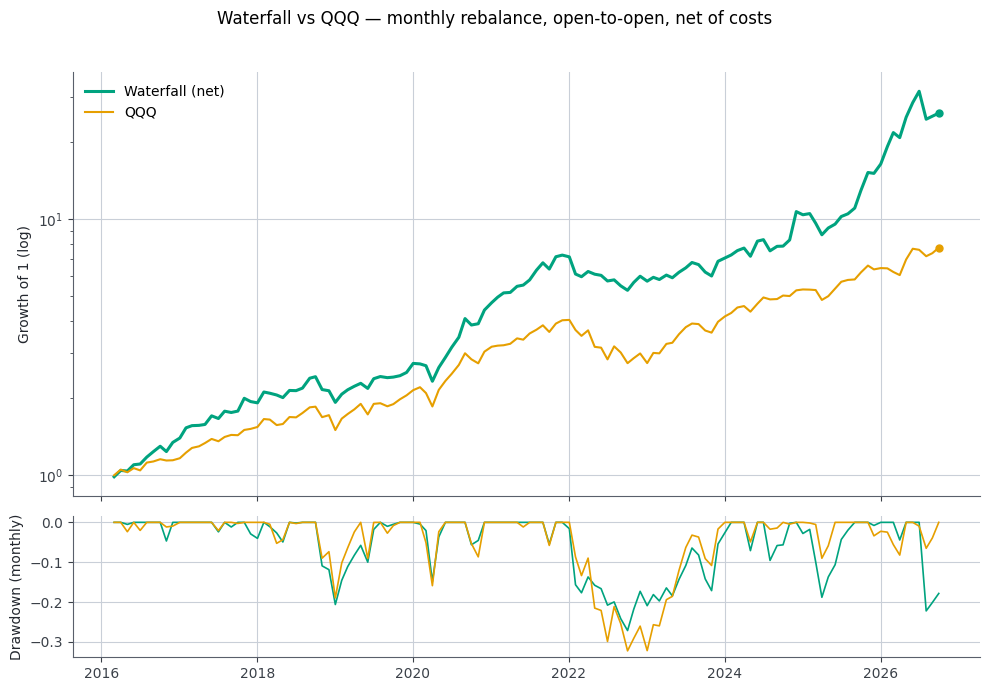

In [6]:
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(10, 7), gridspec_kw={"height_ratios": [3, 1]})
for s, name, c, lw in [(S, "Waterfall (net)", "#00a37f", 2.2), (B, "QQQ", "#e69f00", 1.5)]:
    eq = (1 + s).cumprod()
    ax[0].plot(eq, label=name, color=c, lw=lw)
    ax[0].plot(eq.index[-1:], [eq.iloc[-1]], "o", color=c, ms=5, zorder=5)      # end marker
    ax[1].plot(eq / eq.cummax() - 1, color=c, lw=1.2)
ax[0].set_yscale("log"); ax[0].set_ylabel("Growth of 1 (log)"); ax[0].legend(frameon=False)
ax[1].set_ylabel("Drawdown (monthly)")
fig.suptitle("Waterfall vs QQQ — monthly rebalance, open-to-open, net of costs")
plt.tight_layout(rect=(0, 0, 1, .96)); plt.show()

---
## 4. Walk-forward folds — is the edge consistent?

The track record is cut into **independent, non-overlapping 12-month folds**. In each fold nothing was fitted on that data, so each is a clean out-of-sample test of the *frozen* rule. A single total can hide the fact that one spectacular year did all the work; the fold view cannot.

Two numbers summarise it: the **hit rate** (folds in which the strategy beat QQQ) and an exact **one-sided binomial p-value** — the probability of seeing at least that many wins if each fold were a coin flip.

In [7]:
def fold_table(s, b, size=FOLD, min_len=6):
    rows = []
    for i in range(0, len(s), size):
        k = slice(i, i + size)
        ss, bb = s.iloc[k], b.iloc[k]
        if len(ss) < min_len:            # tiny tail fold is dropped (too noisy to judge)
            continue
        rs, rb = (1 + ss).prod() - 1, (1 + bb).prod() - 1
        rows.append({"Fold": len(rows) + 1, "From": ss.index[0].date(), "To": ss.index[-1].date(),
                     "Months": len(ss), "Waterfall": rs, "QQQ": rb, "Active": rs - rb, "Win": rs > rb})
    return pd.DataFrame(rows).set_index("Fold")

def binom_p(wins, n):                    # P(X >= wins), X ~ Binomial(n, 0.5)
    return sum(comb(n, k) for k in range(wins, n + 1)) / 2 ** n

folds = fold_table(S, B)
print(f"Folds beating QQQ: {folds.Win.sum()} / {len(folds)}   |   exact binomial p = "
      f"{binom_p(int(folds.Win.sum()), len(folds)):.3f}")
folds

Folds beating QQQ: 8 / 11   |   exact binomial p = 0.113


,From,To,Months,Waterfall,QQQ,Active,Win
Fold,,,,,,,
1,2016-03-01,2017-02-01,12,0.530,0.224,0.306,True
2,2017-03-01,2018-02-01,12,0.380,0.352,0.028,True
3,2018-03-01,2019-02-01,12,-0.020,0.004,-0.023,False
4,2019-03-01,2020-02-03,12,0.313,0.326,-0.013,False
5,2020-03-02,2021-02-01,12,0.822,0.453,0.369,True
6,2021-03-01,2022-02-01,12,0.232,0.151,0.080,True
7,2022-03-01,2023-02-01,12,-0.029,-0.186,0.157,True
8,2023-03-01,2024-02-01,12,0.223,0.432,-0.210,False
9,2024-03-01,2025-02-03,12,0.451,0.233,0.217,True


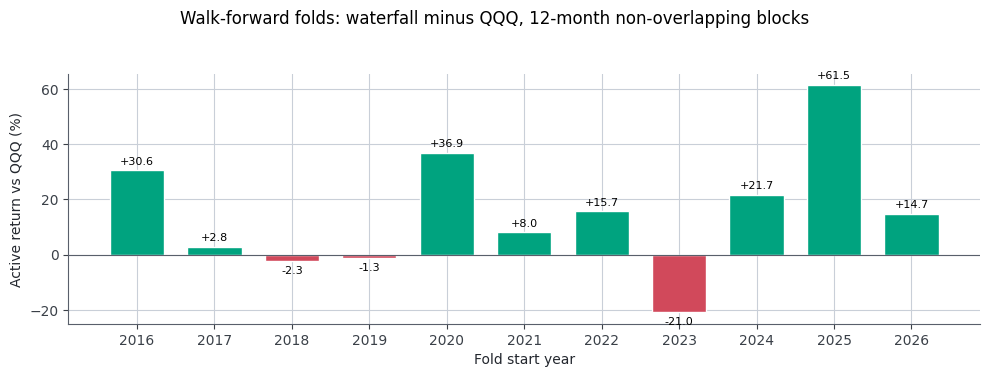

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.8))
vals = folds.Active * 100
bars = ax.bar(folds.index, vals, width=.7, color=np.where(vals > 0, "#00a37f", "#d1495b"), edgecolor="white")
for b, v in zip(bars, vals):                                   # value label above/below each bar
    ax.annotate(f"{v:+.1f}", (b.get_x() + b.get_width() / 2, v), textcoords="offset points",
                xytext=(0, 3 if v >= 0 else -3), ha="center", va="bottom" if v >= 0 else "top", fontsize=8)
ax.axhline(0, color="#595f6b", lw=.8)
ax.set_xticks(folds.index); ax.set_xticklabels([f"{d.year}" for d in folds.From])
ax.set_ylabel("Active return vs QQQ (%)"); ax.set_xlabel("Fold start year")
fig.suptitle("Walk-forward folds: waterfall minus QQQ, 12-month non-overlapping blocks")
plt.tight_layout(rect=(0, 0, 1, .94)); plt.show()

**Reading.** The strategy wins in 8 of the 11 one year folds, which still sounds solid. But the exact binomial p has moved to 0.113, so consistency across folds no longer clears even a lenient 10% bar. The three losing blocks are instructive: Mar 2018 to Feb 2019, Mar 2019 to Feb 2020 (when QQQ itself rose 33%), and Mar 2023 to Feb 2024 (QQQ +43%, strategy +22%). The edge is real but lumpy; it is not a coin flip that wins every year.

---
## 5. Evidence accumulation — does the case get stronger, and does it stay strong?

Here the walk-forward is applied to the **statistic itself**. At each month *m* we use only the history up to *m* and compute the t-statistic of the mean monthly active return (strategy − QQQ). Two things are being checked:

- does the t-stat **climb and stay above ~2** as data accumulates (a real edge accumulates evidence ∝ √time), or does it spike and decay (an episode)?
- the **rolling 36-month active return**: how often is a three-year investor ahead of QQQ?

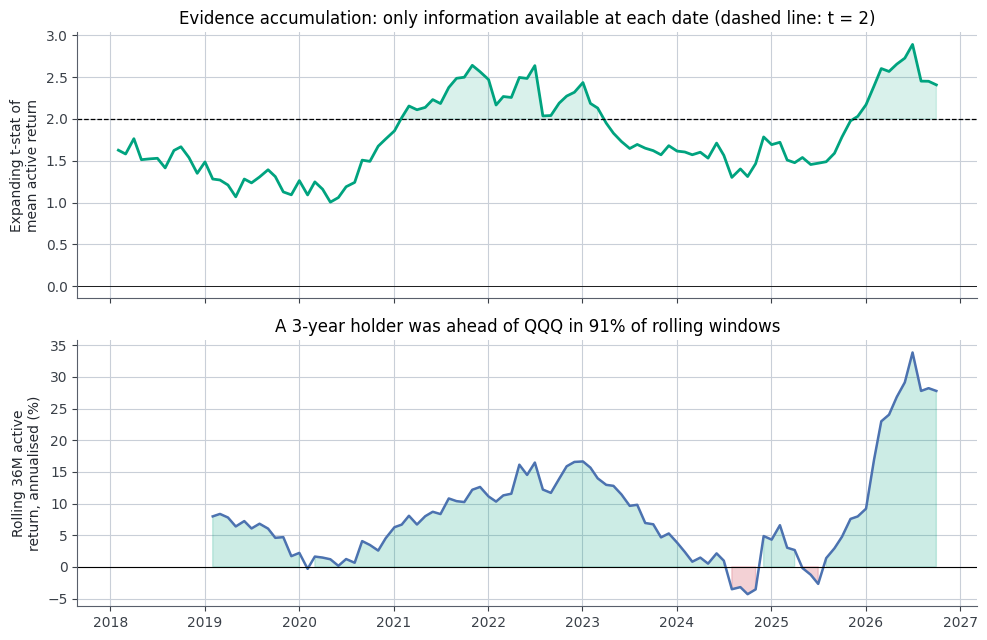

In [9]:
MIN_M  = 24
cnt    = np.arange(1, len(A) + 1)
t_exp  = (A.expanding().mean() / (A.expanding().std() / np.sqrt(cnt)))
t_exp  = t_exp.iloc[MIN_M - 1:]
roll36 = A.rolling(36).mean().dropna() * 12
share_roll = (roll36 > 0).mean()

fig, ax = plt.subplots(2, 1, sharex=True, figsize=(10, 6.5))
ax[0].plot(t_exp, color="#00a37f", lw=2)
ax[0].axhline(2, color="k", ls="--", lw=.9); ax[0].axhline(0, color="k", lw=.6)
ax[0].fill_between(t_exp.index, 2, t_exp.where(t_exp > 2), color="#00a37f", alpha=.15)
ax[0].set_ylabel("Expanding t-stat of\nmean active return")
ax[0].set_title("Evidence accumulation: only information available at each date (dashed line: t = 2)")
ax[1].plot(roll36 * 100, color="#4c72b0", lw=1.8)
ax[1].axhline(0, color="k", lw=.8)
ax[1].fill_between(roll36.index, 0, roll36 * 100, where=roll36 > 0, color="#00a37f", alpha=.2)
ax[1].fill_between(roll36.index, 0, roll36 * 100, where=roll36 <= 0, color="#d1495b", alpha=.25)
ax[1].set_ylabel("Rolling 36M active\nreturn, annualised (%)")
ax[1].set_title(f"A 3-year holder was ahead of QQQ in {share_roll:.0%} of rolling windows")
plt.tight_layout(); plt.show()

---
## 6. Statistical significance

Monthly active returns are autocorrelated, fat-tailed and heteroskedastic, so a naive t-test overstates confidence. Three tests that respect that:

| Test | What it answers | Robustness |
|---|---|---|
| **Robust t-test of the mean active return** (Newey West estimator) | Is outperformance different from zero? | Standard errors robust to autocorrelation and heteroskedasticity (HAC) |
| **CAPM alpha vs QQQ** (HAC) | Is the edge *after* removing market exposure — or just leveraged beta? | Same HAC errors; reports **beta** too |
| **Paired block bootstrap** (6-month blocks, 10,000 resamples) | Distribution-free p-value and 95% CI for (a) annual active return and (b) the **Sharpe difference** | No normality assumption; blocks keep serial dependence; strategy and QQQ are resampled *together* |

A 10-stock momentum book is typically high-beta, so the alpha line matters more than the raw outperformance: a strategy that simply owns QQQ with leverage would "beat" it in a bull market with zero skill.

In [10]:
def nw_t(x, lags=HAC_LAGS):
    '''t-stat of the mean with robust HAC (Newey West type) standard error.'''
    x = np.asarray(x); n = len(x); e = x - x.mean()
    v = e @ e / n
    for l in range(1, lags + 1):
        v += 2 * (1 - l / (lags + 1)) * (e[l:] @ e[:-l]) / n
    return x.mean() / np.sqrt(v / n)

def ols_hac(y, x, lags=HAC_LAGS):
    '''OLS y = a + b·x with robust HAC covariance → coefficients and t-stats.'''
    X = np.column_stack([np.ones(len(x)), x])
    XtXi = np.linalg.inv(X.T @ X)
    b = XtXi @ X.T @ y
    u = X * (y - X @ b)[:, None]
    S = u.T @ u
    for l in range(1, lags + 1):
        G = u[l:].T @ u[:-l]
        S += (1 - l / (lags + 1)) * (G + G.T)
    V = XtXi @ S @ XtXi
    return b, b / np.sqrt(np.diag(V))

def sharpe_rows(X, rf=RF):                           # Sharpe of each row of a (sims × months) matrix
    return (X.mean(1) - rf / 12) * 12 / (X.std(1, ddof=1) * np.sqrt(12))

def battery(s, b, seed=7):
    '''Full significance battery of series s against benchmark b (monthly returns).'''
    s, b = s.align(b, join="inner")
    sv, bv = s.values, b.values
    a, n = sv - bv, len(sv)

    coef, tv = ols_hac(sv, bv)
    f  = fold_table(s, b)
    ra = pd.Series(a).rolling(36).mean().dropna() * 12

    rng   = np.random.default_rng(seed)               # circular paired block bootstrap
    nb    = int(np.ceil(n / BLOCK))
    idx   = ((rng.integers(0, n, (NSIM, nb))[:, :, None] + np.arange(BLOCK)) % n).reshape(NSIM, -1)[:, :n]
    Sb, Bb = sv[idx], bv[idx]
    act_b = (Sb - Bb).mean(1) * 12
    dsh_b = sharpe_rows(Sb) - sharpe_rows(Bb)

    return {
        "Months": n,
        "Active return (ann.)": a.mean() * 12,
        "HAC t-stat (active return)": nw_t(a),
        "CAPM alpha (ann.)": coef[0] * 12,
        "t-stat of alpha, HAC": tv[0],
        "Beta vs benchmark": coef[1],
        "Sharpe difference": sharpe_rows(sv[None])[0] - sharpe_rows(bv[None])[0],
        "Bootstrap p: active ≤ 0": (act_b <= 0).mean(),
        "Bootstrap p: ΔSharpe ≤ 0": (dsh_b <= 0).mean(),
        "Folds won": f"{int(f.Win.sum())}/{len(f)}",
        "Binomial p (folds)": binom_p(int(f.Win.sum()), len(f)),
        "Rolling 36M ahead": (ra > 0).mean(),
        "_act_boot": act_b, "_dsh_boot": dsh_b,
    }

vs_qqq = battery(S, B)

In [11]:
def show(res_dict):
    return pd.DataFrame({k: {m: v for m, v in r.items() if not m.startswith("_")}
                         for k, r in res_dict.items()})

show({"Waterfall vs QQQ": vs_qqq})

,Waterfall vs QQQ
Active return (ann.),0.128
Beta vs benchmark,0.953
Binomial p (folds),0.113
Bootstrap p: active ≤ 0,0.008
Bootstrap p: ΔSharpe ≤ 0,0.167
CAPM alpha (ann.),0.138
Folds won,8/11
HAC t-stat (active return),2.187
Months,128
Rolling 36M ahead,0.914


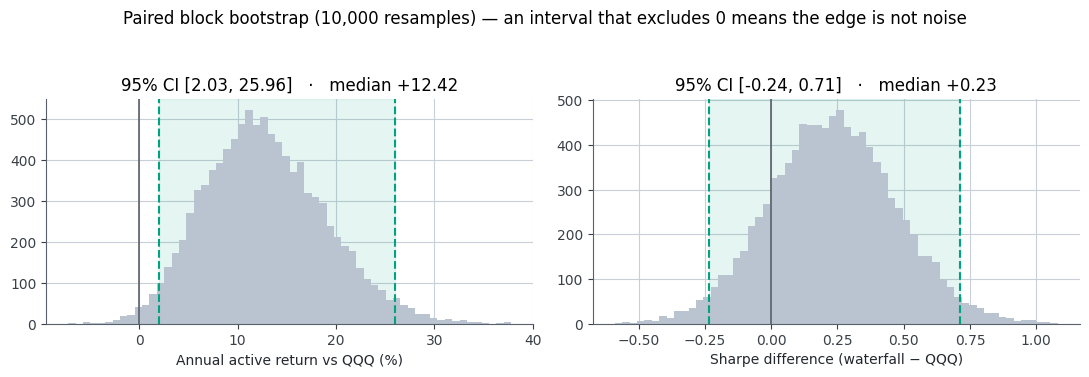

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, key, scale, lab in [(ax[0], "_act_boot", 100, "Annual active return vs QQQ (%)"),
                           (ax[1], "_dsh_boot", 1,   "Sharpe difference (waterfall − QQQ)")]:
    x = np.asarray(vs_qqq[key]) * scale
    lo, hi = np.percentile(x, [2.5, 97.5])
    a.axvspan(lo, hi, color="#00a37f", alpha=.10)                        # CI band behind the histogram
    a.hist(x, bins=60, color="#b9c4d0", histtype="stepfilled")
    a.axvline(0, color="#595f6b", lw=1.2)
    a.axvline(lo, color="#00a37f", ls="--"); a.axvline(hi, color="#00a37f", ls="--")
    a.set_xlabel(lab); a.set_title(f"95% CI [{lo:.2f}, {hi:.2f}]   ·   median {np.median(x):+.2f}")
fig.suptitle("Paired block bootstrap (10,000 resamples) — an interval that excludes 0 means the edge is not noise")
plt.tight_layout(rect=(0, 0, 1, .93)); plt.show()

**Reading.** The case now rests on two legs. Outperformance holds under robust HAC inference (t near 2.2), and the paired block bootstrap puts P(active ≤ 0) at about one percent. The Sharpe difference alone does not clear its bar (p = 0.167). So what we can claim is a positive, statistically credible return edge after beta; what we cannot yet claim is a reliably higher risk adjusted score.

---
## 7. Scorecard

Each criterion is computed from the numbers above — nothing is typed by hand. Thresholds are conventional rules of thumb (5% one-sided for the main tests, 10% for the binomial test because there are only ~10 folds). A ✗ means *"claim not supported by this evidence"*, not *"strategy is worthless"*.

In [13]:
def scorecard(r, label):
    checks = {
        "Outperforms: active return > 0 and HAC t > 2":        r["Active return (ann.)"] > 0 and r["HAC t-stat (active return)"] > 2,
        "Alpha after beta: CAPM alpha > 0 and HAC t > 2":      r["CAPM alpha (ann.)"] > 0 and r["t-stat of alpha, HAC"] > 2,
        "Bootstrap: P(active ≤ 0) < 5%":                       r["Bootstrap p: active ≤ 0"] < .05,
        "Bootstrap: P(ΔSharpe ≤ 0) < 5%":                      r["Bootstrap p: ΔSharpe ≤ 0"] < .05,
        "Consistency: folds won, binomial p < 10%":            r["Binomial p (folds)"] < .10,
        "Persistence: ahead in ≥ 75% of rolling 36M windows":  r["Rolling 36M ahead"] >= .75,
    }
    print(f"── {label} " + "─" * (60 - len(label)))
    for k, v in checks.items():
        print(f"  {'✓' if v else '✗'}  {k}")
    print(f"  → {sum(checks.values())}/{len(checks)} passed | active {r['Active return (ann.)']:.1%}/yr | "
          f"alpha {r['CAPM alpha (ann.)']:.1%}/yr | beta {r['Beta vs benchmark']:.2f} | folds won {r['Folds won']}\n")
    return sum(checks.values()), len(checks)

k, tot = scorecard(vs_qqq, "Waterfall (net) vs QQQ")

── Waterfall (net) vs QQQ ──────────────────────────────────────
  ✓  Outperforms: active return > 0 and HAC t > 2
  ✓  Alpha after beta: CAPM alpha > 0 and HAC t > 2
  ✓  Bootstrap: P(active ≤ 0) < 5%
  ✗  Bootstrap: P(ΔSharpe ≤ 0) < 5%
  ✗  Consistency: folds won, binomial p < 10%
  ✓  Persistence: ahead in ≥ 75% of rolling 36M windows
  → 4/6 passed | active 12.8%/yr | alpha 13.8%/yr | beta 0.95 | folds won 8/11



**Reading.** Four of the six checks pass against QQQ: outperformance, alpha after beta, bootstrap significance on active return, and persistence across rolling windows. The two that fail are the stricter ones (Sharpe difference and fold consistency). The honest summary is a credible return edge with an unproven Sharpe edge.

## 8. The lookahead bias check: same strategy, today's membership

So far every universe decision used actual index membership at each date. Now the classic shortcut: run the **identical** waterfall (same signals, same funnel, same costs, same dates) with **today's index membership applied to every month since 2016**. That is the backtest most people would ship, and it silently gives the strategy its future self. Section by section we compare results and statistical validation: real case membership vs today's membership (lookahead).

In [14]:
def waterfall_biased(t, n1=N1, n2=N2, n3=N3):
    pool = [x for x in CURRENT if x in close.columns]     # today's members at every date: the lookahead set
    p = m12.loc[t, pool].dropna().nlargest(n1).index
    p = m6.loc[t, p].dropna().nlargest(n2).index
    return m3.loc[t, p].dropna().nlargest(n3).index

S_bias = backtest(waterfall_biased).net                    # everything identical to the real case except the universe
cmp_perf = pd.DataFrame({
    "QQQ (benchmark)": perf(B),
    "Real case membership": perf(S),
    "Today's membership (lookahead)": perf(S_bias),
}).T
print(f"Universe: {int(pool.__len__())} tickers at every date with today's membership, vs 107 to 113 actual members in the real case")
cmp_perf

Universe: 128 tickers at every date with today's membership, vs 107 to 113 actual members in the real case


,CAGR,Vol,Sharpe,MaxDD,Best month,Worst month,% months > 0
QQQ (benchmark),0.211,0.192,1.102,-0.322,0.161,-0.138,0.664
Real case membership,0.357,0.252,1.347,-0.271,0.290,-0.222,0.664
Today's membership (lookahead),0.511,0.302,1.531,-0.274,0.510,-0.274,0.695


**Reading.** Lookahead does a lot of work here. With today's membership at every date the strategy compounds 51% a year (Sharpe 1.53); with actual membership it earns 36% (Sharpe 1.35), while QQQ sits at 21% (Sharpe 1.10). Volatility climbs from about 25% to 30% as well, so part of the extra return is simply owning the winners before everyone else does. In the chart above, the vertical gap between the two strategy lines **is** the size of the membership bias.

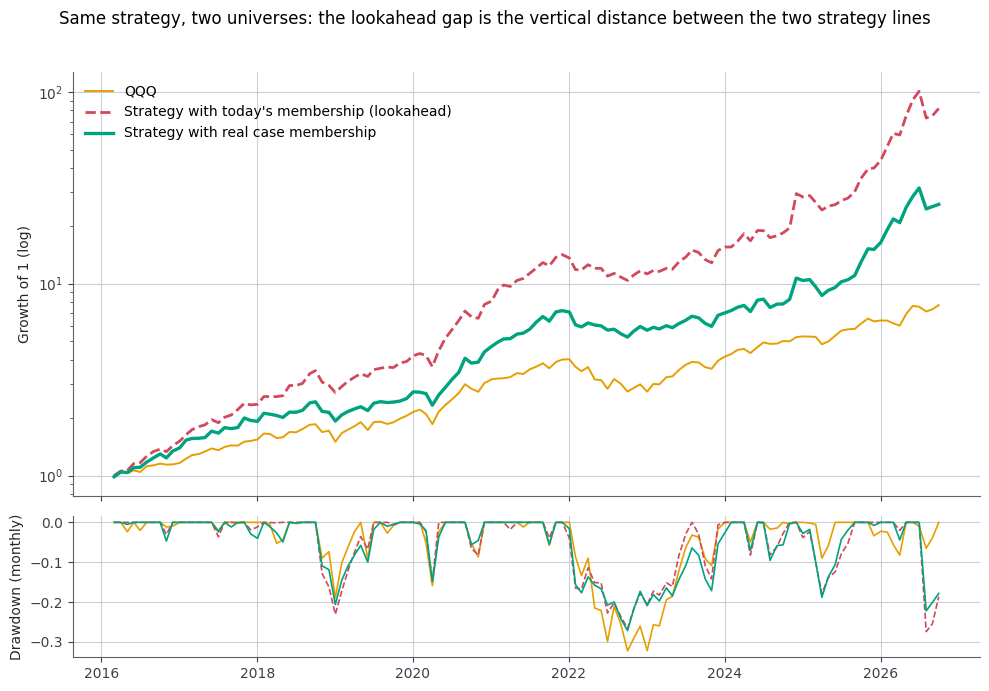

In [15]:
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(10, 7), gridspec_kw={"height_ratios": [3, 1]})
for s, name, c, lw, ls in [(B,      "QQQ",                                        "#e69f00", 1.4, "-"),
                           (S_bias, "Strategy with today's membership (lookahead)", "#d1495b", 2.0, "--"),
                           (S,      "Strategy with real case membership",            "#00a37f", 2.4, "-")]:
    eq = (1 + s).cumprod()
    ax[0].plot(eq, label=name, color=c, lw=lw, ls=ls)
    ax[1].plot(eq / eq.cummax() - 1, color=c, lw=1.2, ls=ls)
ax[0].set_yscale("log"); ax[0].set_ylabel("Growth of 1 (log)"); ax[0].legend(frameon=False)
ax[1].set_ylabel("Drawdown (monthly)")
fig.suptitle("Same strategy, two universes: the lookahead gap is the vertical distance between the two strategy lines")
plt.tight_layout(rect=(0, 0, 1, .96)); plt.show()

In [16]:
bat_bias = battery(S_bias, B)                              # full significance battery, same tests as section 7
cmp_stat = pd.DataFrame({
    "real case":     {k: v for k, v in vs_qqq.items() if not k.startswith("_")},
    "with lookahead": {k: v for k, v in bat_bias.items() if not k.startswith("_")},
})
scorecard(bat_bias, "Waterfall (net) vs QQQ — with today's membership at every date")
cmp_stat

── Waterfall (net) vs QQQ — with today's membership at every date 
  ✓  Outperforms: active return > 0 and HAC t > 2
  ✓  Alpha after beta: CAPM alpha > 0 and HAC t > 2
  ✓  Bootstrap: P(active ≤ 0) < 5%
  ✓  Bootstrap: P(ΔSharpe ≤ 0) < 5%
  ✓  Consistency: folds won, binomial p < 10%
  ✓  Persistence: ahead in ≥ 75% of rolling 36M windows
  → 6/6 passed | active 25.1%/yr | alpha 23.7%/yr | beta 1.07 | folds won 10/11



,real case,with lookahead
Months,128,128
Active return (ann.),0.128,0.251
HAC t-stat (active return),2.187,3.494
CAPM alpha (ann.),0.138,0.237
"t-stat of alpha, HAC",2.271,3.318
Beta vs benchmark,0.953,1.069
Sharpe difference,0.245,0.429
Bootstrap p: active ≤ 0,0.008,0.000
Bootstrap p: ΔSharpe ≤ 0,0.167,0.036
Folds won,8/11,10/11


**Reading.** Here it gets interesting. Both versions beat QQQ convincingly on active return and CAPM alpha (HAC t between about 2.2 and 3.5), and the bootstrap probability of losing money is near zero in both. The difference shows up in the two stricter checks. With today's membership, P(ΔSharpe ≤ 0) drops from 0.17 to 0.04 (pass instead of fail), and fold consistency improves from 8 wins out of 11 (binomial p = 0.113) to 10 out of 11 (p = 0.006). The perfect six of six scorecard is therefore a product of membership lookahead; the real case earns four of six, with outperformance and alpha still significant while Sharpe difference and fold consistency miss their bars.

---
## 9. How far can this conclusion be pushed?

A significant result against QQQ is **necessary, not sufficient**. The honest boundaries:

**1. Membership timing (quantified in section 8).** The universe uses point-in-time membership from `inout.xlsx`: a recorded addition only becomes eligible in the year *after* its addition year (its whole addition year is ignored), and a removal stays eligible through its exit year, so no signal relies on information that had not yet become public. Residual approximations: (i) effective dates within a year are unknown; (ii) current members with no recorded change are assumed to have been in the index since before 2015; (iii) tickers without downloadable price history drop out wherever they would be needed. The cell below runs the *same battery* against an **equal-weight portfolio of the same universe**: if the waterfall's edge over *that* is weak, much of the advantage over QQQ is simply "owning today's winners". Passing this is necessary, still not proof.

**2. Hindsight in the design.** No parameters were searched, but 12/6/3 months and 50/25/10 were chosen by someone who had seen this history. Only genuinely new data — a forward test — removes this.

**3. One regime.** About ten years dominated by US mega-cap tech. The Sharpe ratio's standard error at this length is roughly 0.3.

**4. Simplified costs.** Flat 10 bp on traded notional; no market impact, no taxes.

**5. Multiple tests.** The scorecard reports six related criteria; they are correlated, not independent, but a single ✓ among ✗s should not be oversold.

In [17]:
vs_ew = battery(S, ew.gross)       # same universe, equal-weight, no skill — the membership-adjusted yardstick
k2, tot2 = scorecard(vs_ew, "Waterfall (net) vs equal-weight universe")
show({"vs QQQ": vs_qqq, "vs equal-weight universe": vs_ew})

── Waterfall (net) vs equal-weight universe ────────────────────
  ✓  Outperforms: active return > 0 and HAC t > 2
  ✓  Alpha after beta: CAPM alpha > 0 and HAC t > 2
  ✓  Bootstrap: P(active ≤ 0) < 5%
  ✗  Bootstrap: P(ΔSharpe ≤ 0) < 5%
  ✗  Consistency: folds won, binomial p < 10%
  ✓  Persistence: ahead in ≥ 75% of rolling 36M windows
  → 4/6 passed | active 13.6%/yr | alpha 14.0%/yr | beta 0.98 | folds won 8/11



,vs QQQ,vs equal-weight universe
Months,128,128
Active return (ann.),0.128,0.136
HAC t-stat (active return),2.187,2.348
CAPM alpha (ann.),0.138,0.140
"t-stat of alpha, HAC",2.271,2.564
Beta vs benchmark,0.953,0.978
Sharpe difference,0.245,0.231
Bootstrap p: active ≤ 0,0.008,0.004
Bootstrap p: ΔSharpe ≤ 0,0.167,0.162
Folds won,8/11,8/11


**Reading.** The same battery passes against an equal weight basket of real index membership: about 14% active return per year, HAC t near 2.4 to 2.6, and P(active ≤ 0) at 0.4%. Simply owning today's winners therefore does not explain the whole edge. What it also cannot fix is the same pair of failures (Sharpe difference, fold consistency), which persist against both benchmarks.

**Next steps to make the claim stronger:** (1) exact effective dates for each addition/removal in `inout.xlsx` (currently year-resolution); (2) extend to Russell 1000 / global equities as a genuinely different sample; (3) regress on Fama-French + momentum factors to see whether the alpha is more than known factor exposure; (4) paper-trade and accumulate a live forward record before sizing up.

---
*Research for educational purposes. Nothing herein constitutes investment advice.*

## 10. Main findings

This notebook runs the same strategy twice and puts both against QQQ, because the comparison itself is the story: benchmark versus strategy with membership lookahead versus real case.

Net of costs, the real case waterfall beats QQQ by about 13% a year (CAGR 36% against 21%, Sharpe 1.35 against 1.10), with a marginally shallower drawdown. That outperformance is statistically credible: HAC t near 2.2 on active return, positive CAPM alpha after beta (t near 2.3), and a bootstrap probability of losing money below one percent.

What does not survive is the finer print. With actual membership the strategy wins in only 8 of the 11 independent folds, each one year long (binomial p = 0.113), and the Sharpe difference misses its bar (P(ΔSharpe ≤ 0) = 0.17). Scorecard: four of six.

The lookahead run explains exactly that gap. With today's membership at every date, CAGR climbs from 36% to 51%, and both failed checks flip to pass (P(ΔSharpe ≤ 0) = 0.04; folds won 10 out of 11, p = 0.006). Scorecard: six of six. In other words, the perfect statistical validation is a product of membership lookahead; in the real case only outperformance and alpha remain significant.

The practical takeaway: momentum selection over this index has a genuine but moderate edge over holding QQQ, and how much of it you keep depends on picking from actual members at each date rather than from today's list. Twenty five historical constituents had no downloadable price history and were excluded wherever needed (the list is in section 1).
